# 10 — Figures for the report

All 14 figures of the report, redrawn in one consistent style (`src/report_style.py`): dark muted colours, Times
font, white background, **no title inside the figures** (the caption of the report gives it). Series are
distinguished by colour *and* line style, so the figures stay readable in black and white.

The figures are saved in `figures/` (PNG, 300 dpi), numbered in the order of the report outline (README).
This notebook reads the results saved by notebooks 02–09; a few curves that were not saved (SARSA and Monte Carlo
on four letters, delayed reward) are recomputed. **Run time: about 5 minutes.**

| File | Report section | Content |
|---|---|---|
| `fig01_letters.png` | 2.1 | The 26 letters (10 training letters framed) and their natural starting points |
| `fig02_optimal_drawings.png` | 3.1 | Optimal drawings (value iteration) |
| `fig03_convergence.png` | 3.1 | Convergence of value iteration |
| `fig04_q_learning_curves.png` | 3.2 | Q-learning learning curves (5 runs) |
| `fig05_tabular_comparison.png` | 3.2 | Q-learning, SARSA and Monte Carlo on four letters |
| `fig06_monte_carlo_trap.png` | 3.2 | Monte Carlo "gives up" |
| `fig07_method_summary.png` | 3.2 / 4 | All methods compared |
| `fig08_writing_style.png` | 3.3 | Writing style for three rewards |
| `fig09_early_stop_penalty.png` | 3.3 | Early-stop penalty: Monte Carlo vs Q-learning |
| `fig10_delayed_reward.png` | 3.3 | Shaped vs delayed reward (Q-learning) |
| `fig11_dqn_learning.png` | 3.4 | DQN learning curves (3 runs) |
| `fig12_generalisation.png` | 3.5 | The 2 × 2 generalisation design |
| `fig13_unseen_letters.png` | 3.5 | The 26 letters drawn by network B, which never saw them |
| `fig14_unseen_failures_07.png` | 3.5 | The network of notebook 07 on the 16 unseen letters |

In [1]:
import sys
sys.path.insert(0, "..")

import csv
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch

from src.letters import make_letter, TRAINING_LETTERS, TEST_LETTERS
from src.environment import LetterWritingEnv, Rewards
from src.dynamic_programming import value_iteration
from src.tabular_agents import q_learning, sarsa, monte_carlo
from src.evaluation import play_policy, greedy_policy
from src.dqn import QNetwork, greedy_episode, obs_size
from src import report_style as rs

rs.apply()
torch.set_num_threads(1)
GAMMA = 0.99
FIG = "../figures"
os.makedirs(FIG, exist_ok=True)
t_start = time.perf_counter()

def save(fig, name):
    fig.savefig(f"{FIG}/{name}")
    print(f"saved figures/{name}")

v_star = {}
with open("../results/02_optimal_returns.csv") as f:
    for row in csv.DictReader(f):
        v_star.setdefault(row["letter"], []).append(float(row["v_star"]))
v_star = {k: np.mean(v) for k, v in v_star.items()}

## Figure 1 — The 26 letters

saved figures/fig01_letters.png


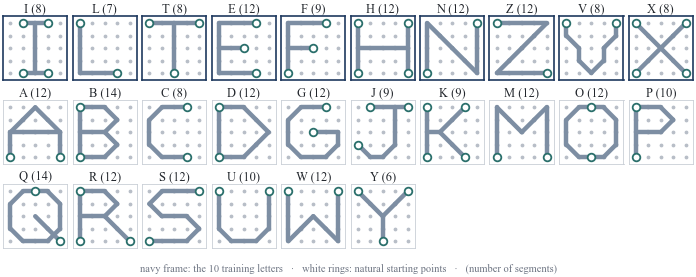

In [2]:
fig, axes = rs.panel_grid(26, 10, panel=0.7)
for ax, name in zip(axes, TRAINING_LETTERS + TEST_LETTERS):
    letter = make_letter(name)
    rs.draw_letter(ax, letter, title=f"{name} ({letter.n_segments})", highlight=name in TRAINING_LETTERS)
rs.add_caption_line(fig, "navy frame: the 10 training letters   ·   white rings: natural starting points   ·   "
                         "(number of segments)")
fig.tight_layout(pad=0.4)
save(fig, "fig01_letters.png")
plt.show()

## Figures 2–3 — Value iteration: optimal drawings and convergence

saved figures/fig02_optimal_drawings.png


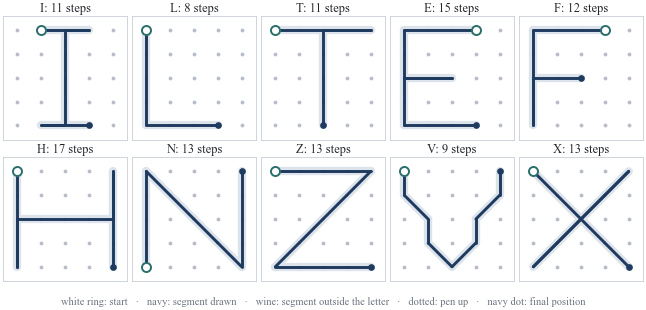

saved figures/fig03_convergence.png


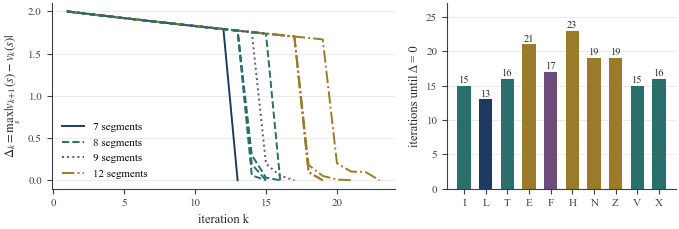

In [3]:
vi_results = {}
for name in TRAINING_LETTERS:
    env = LetterWritingEnv(name)
    vi = value_iteration(env, gamma=GAMMA)
    ep = play_policy(env, vi["policy"], env.letter.start_points[0], gamma=GAMMA)
    vi_results[name] = (env, vi, ep)

fig, axes = rs.panel_grid(10, 5, panel=1.3)
for ax, (name, (env, vi, ep)) in zip(axes, vi_results.items()):
    rs.draw_episode(ax, env.letter, ep["history"], f"{name}: {ep['steps']} steps")
rs.add_caption_line(fig)
fig.tight_layout(pad=0.4)
save(fig, "fig02_optimal_drawings.png")
plt.show()

groups = sorted({env.k for env, _, _ in vi_results.values()})
group_style = {k: (rs.SERIES[i], rs.LINESTYLES[i]) for i, k in enumerate(groups)}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(rs.WIDTH, 2.5), gridspec_kw={"width_ratios": [1.5, 1]})
for name, (env, vi, _) in vi_results.items():
    color, ls = group_style[env.k]
    ax1.plot(range(1, len(vi["deltas"]) + 1), vi["deltas"], color=color, ls=ls, lw=1.4)
ax1.legend([plt.Line2D([], [], color=group_style[k][0], ls=group_style[k][1], lw=1.4) for k in groups],
           [f"{k} segments" for k in groups], loc="lower left")
rs.axes_style(ax1, "iteration k", r"$\Delta_k = \max_s |v_{k+1}(s) - v_k(s)|$")
iters = [len(vi_results[n][1]["deltas"]) for n in TRAINING_LETTERS]
ax2.bar(TRAINING_LETTERS, iters, color=[group_style[vi_results[n][0].k][0] for n in TRAINING_LETTERS], width=0.62)
for x, y in enumerate(iters):
    ax2.text(x, y + 0.4, str(y), ha="center", fontsize=7.5, color=rs.TEXT)
ax2.set_ylim(0, max(iters) + 4)
rs.axes_style(ax2, None, "iterations until Δ = 0")
fig.tight_layout()
save(fig, "fig03_convergence.png")
plt.show()

## Figure 4 — Q-learning learning curves (5 runs, notebook 03)

saved figures/fig04_q_learning_curves.png


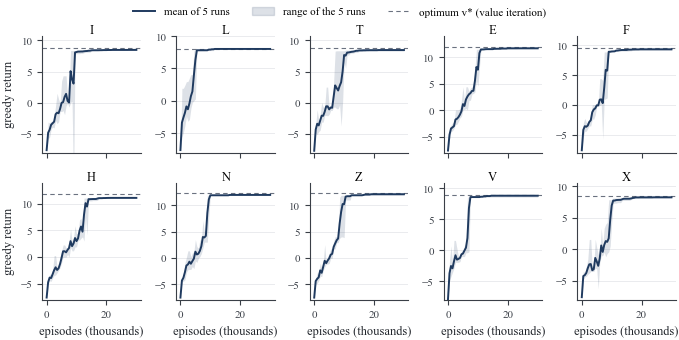

In [4]:
q_curves = np.load("../results/03_q_learning_curves.npz")
episodes = q_curves["episodes"]
fig, axes = plt.subplots(2, 5, figsize=(rs.WIDTH, 3.4), sharex=True)
for ax, name in zip(axes.ravel(), TRAINING_LETTERS):
    c = q_curves[f"{name}_return"]
    ax.axhline(v_star[name], color=rs.SLATE, lw=0.8, ls=(0, (4, 3)))
    ax.fill_between(episodes / 1000, c.min(0), c.max(0), color=rs.NAVY, alpha=0.15, lw=0)
    ax.plot(episodes / 1000, c.mean(0), color=rs.NAVY, lw=1.4)
    ax.set_ylim(-8, v_star[name] + 2)
    ax.set_title(name, pad=2)
    rs.axes_style(ax)
for ax in axes[1]:
    ax.set_xlabel("episodes (thousands)")
for ax in axes[:, 0]:
    ax.set_ylabel("greedy return")
fig.legend([plt.Line2D([], [], color=rs.NAVY, lw=1.4), plt.Rectangle((0, 0), 1, 1, color=rs.NAVY, alpha=0.15),
            plt.Line2D([], [], color=rs.SLATE, lw=0.8, ls=(0, (4, 3)))],
           ["mean of 5 runs", "range of the 5 runs", "optimum v* (value iteration)"],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save(fig, "fig04_q_learning_curves.png")
plt.show()

## Figures 5–6 — Tabular methods compared, and the Monte Carlo trap

Run 0 of each method on four representative letters (recomputed here: notebook 04 did not save its curves),
and the final Monte Carlo drawings on the 10 letters. About 1 minute.

saved figures/fig05_tabular_comparison.png


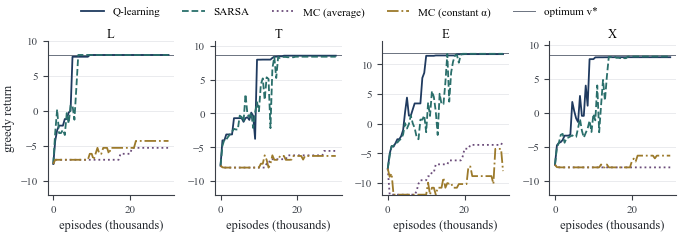

saved figures/fig06_monte_carlo_trap.png


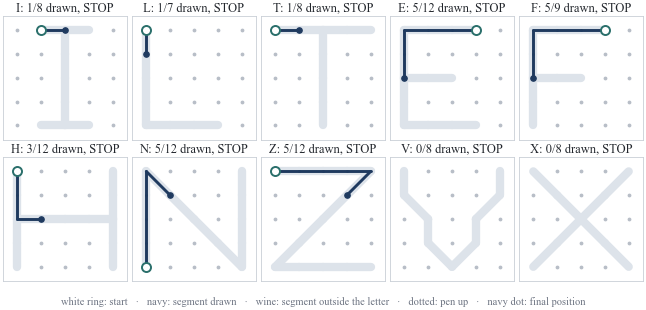

In [5]:
METHODS = [("Q-learning", q_learning, 0.5), ("SARSA", sarsa, 0.1),
           ("MC (average)", monte_carlo, None), ("MC (constant α)", monte_carlo, 0.05)]
SHOWN = ["L", "T", "E", "X"]
tab = {}
for name in TRAINING_LETTERS:
    for label, fn, alpha in METHODS:
        if name in SHOWN or label == "MC (average)":
            res = fn(LetterWritingEnv(name), n_episodes=30_000, alpha=alpha, gamma=GAMMA, seed=0)
            res["policy"] = greedy_policy(res.pop("Q"))
            tab[(name, label)] = res

fig, axes = plt.subplots(1, 4, figsize=(rs.WIDTH, 2.3), sharex=True)
for ax, name in zip(axes, SHOWN):
    ax.axhline(v_star[name], color=rs.SLATE, lw=0.7)
    for (label, _, _), color, ls in zip(METHODS, rs.SERIES, rs.LINESTYLES):
        r = tab[(name, label)]
        ax.plot(r["eval_episodes"] / 1000, r["eval_return"], color=color, ls=ls, lw=1.3)
    ax.set_ylim(-12, v_star[name] + 2)
    ax.set_title(name, pad=2)
    rs.axes_style(ax, "episodes (thousands)")
axes[0].set_ylabel("greedy return")
fig.legend([plt.Line2D([], [], color=c, ls=ls, lw=1.3) for c, ls in zip(rs.SERIES, rs.LINESTYLES)]
           + [plt.Line2D([], [], color=rs.SLATE, lw=0.7)],
           [m[0] for m in METHODS] + ["optimum v*"], loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
save(fig, "fig05_tabular_comparison.png")
plt.show()

fig, axes = rs.panel_grid(10, 5, panel=1.3)
for ax, name in zip(axes, TRAINING_LETTERS):
    env = LetterWritingEnv(name)
    ep = play_policy(env, tab[(name, "MC (average)")]["policy"], env.letter.start_points[0], gamma=GAMMA)
    end = "STOP" if ep["history"][-1]["event"] == "stop" else "step limit"
    rs.draw_episode(ax, env.letter, ep["history"], f"{name}: {ep['drawn']}/{env.k} drawn, {end}")
rs.add_caption_line(fig)
fig.tight_layout(pad=0.4)
save(fig, "fig06_monte_carlo_trap.png")
plt.show()

## Figure 7 — All methods compared on the 10 training letters

Means over the 10 letters and the runs. Value iteration = 100 % by definition; Q-learning, SARSA and Monte Carlo
from `results/04_comparison_summary.csv` (5 runs); DQN from the 3 networks of notebook 07.

saved figures/fig07_method_summary.png


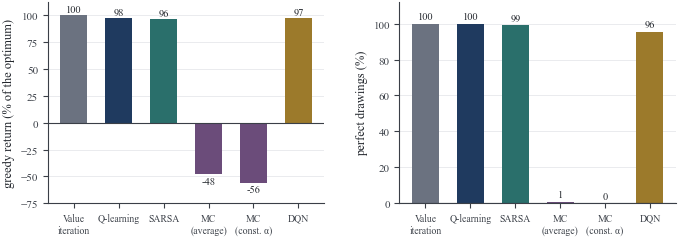

Value iteration     100.0 % of v*   100.0 % perfect
Q-learning           97.6 % of v*   100.0 % perfect
SARSA                96.3 % of v*    99.0 % perfect
MC (average)        -47.8 % of v*     1.0 % perfect
MC (const. α)       -55.9 % of v*     0.0 % perfect
DQN                  97.4 % of v*    95.6 % perfect


In [6]:
summary = {"Value\niteration": (100.0, 100.0)}
by_method = {}
with open("../results/04_comparison_summary.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        by_method.setdefault(row["method"], []).append((float(row["pct_optimum_mean"]), 100 * float(row["perfect_final"])))
labels = {"Q-learning": "Q-learning", "SARSA": "SARSA", "MC (average)": "MC\n(average)", "MC (constant α)": "MC\n(const. α)"}
for method, vals in by_method.items():
    summary[labels[method]] = (np.mean([v[0] for v in vals]), np.mean([v[1] for v in vals]))
pct, perf = [], []
for seed in [0, 1, 2]:
    d = np.load(f"../results/07_dqn_seed{seed}_curves.npz")
    pct.append(np.mean([100 * d["returns"][-1, i] / v_star[n] for i, n in enumerate(TRAINING_LETTERS)]))
    perf.append(100 * d["perfect"][-1].mean())
summary["DQN"] = (np.mean(pct), np.mean(perf))

names = list(summary)
colors = [rs.SLATE, rs.NAVY, rs.TEAL, rs.PLUM, rs.PLUM, rs.OCHRE]
fig, axes = plt.subplots(1, 2, figsize=(rs.WIDTH, 2.6))
for ax, k, ylabel in [(axes[0], 0, "greedy return (% of the optimum)"), (axes[1], 1, "perfect drawings (%)")]:
    vals = [summary[n][k] for n in names]
    ax.bar(range(len(names)), vals, color=colors, width=0.6)
    ax.axhline(0, color=rs.AXIS, lw=0.8)
    for x, v in enumerate(vals):
        ax.text(x, v + (2.5 if v >= 0 else -9), f"{v:.0f}", ha="center", fontsize=7.5, color=rs.TEXT)
    ax.set_xticks(range(len(names)), names, fontsize=7)
    rs.axes_style(ax, None, ylabel)
axes[0].set_ylim(-75, 112)
axes[1].set_ylim(0, 112)
fig.tight_layout(w_pad=2.5)
save(fig, "fig07_method_summary.png")
plt.show()
for n in names:
    print(f"{n.replace(chr(10), ' '):<18} {summary[n][0]:6.1f} % of v*   {summary[n][1]:5.1f} % perfect")

## Figure 8 — Writing style for three rewards (value iteration)

saved figures/fig08_writing_style.png


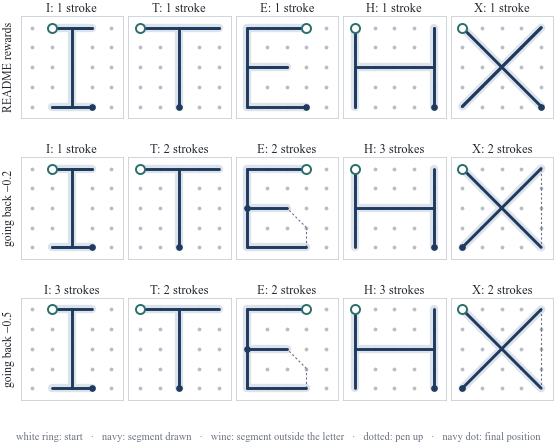

In [7]:
settings = [("README rewards", Rewards()), ("going back −0.2", Rewards(redrawn=-0.2)),
            ("going back −0.5", Rewards(redrawn=-0.5))]
letters_shown = ["I", "T", "E", "H", "X"]
fig, axes = plt.subplots(len(settings), len(letters_shown), figsize=(rs.WIDTH * 0.8, 4.4))
for i, (label, rewards) in enumerate(settings):
    for j, name in enumerate(letters_shown):
        env = LetterWritingEnv(name, rewards=rewards)
        vi = value_iteration(env, gamma=GAMMA)
        ep = play_policy(env, vi["policy"], env.letter.start_points[0], gamma=GAMMA)
        rs.draw_episode(axes[i, j], env.letter, ep["history"], f"{name}: {ep['strokes']} stroke{'s' * (ep['strokes'] > 1)}")
    axes[i, 0].set_ylabel(label, fontsize=8.5)
rs.add_caption_line(fig)
fig.tight_layout(pad=0.4)
save(fig, "fig08_writing_style.png")
plt.show()

## Figure 9 — Early-stop penalty (notebook 06)

saved figures/fig09_early_stop_penalty.png


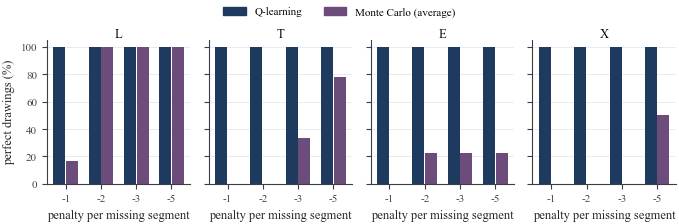

In [8]:
early = {}
with open("../results/06_early_stop_penalty.csv") as f:
    for row in csv.DictReader(f):
        early[(row["letter"], float(row["penalty"]))] = (100 * float(row["q_perfect"]), 100 * float(row["mc_perfect"]))
letters_e = sorted({k[0] for k in early}, key=["L", "T", "E", "X"].index)
penalties = sorted({k[1] for k in early}, reverse=True)
fig, axes = plt.subplots(1, len(letters_e), figsize=(rs.WIDTH, 2.2), sharey=True)
x = np.arange(len(penalties))
for ax, name in zip(axes, letters_e):
    ax.bar(x - 0.18, [early[(name, p)][0] for p in penalties], width=0.34, color=rs.NAVY)
    ax.bar(x + 0.18, [early[(name, p)][1] for p in penalties], width=0.34, color=rs.PLUM)
    ax.set_xticks(x, [f"{p:g}" for p in penalties])
    ax.set_title(name, pad=2)
    rs.axes_style(ax, "penalty per missing segment")
axes[0].set_ylabel("perfect drawings (%)")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=rs.NAVY), plt.Rectangle((0, 0), 1, 1, color=rs.PLUM)],
           ["Q-learning", "Monte Carlo (average)"], loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
save(fig, "fig09_early_stop_penalty.png")
plt.show()

## Figure 10 — Shaped vs delayed reward (Q-learning)

Shaped: notebook 03 (5 runs). Delayed (no +1 per segment): recomputed here, 3 runs as in notebook 06 (about 2 minutes).

saved figures/fig10_delayed_reward.png


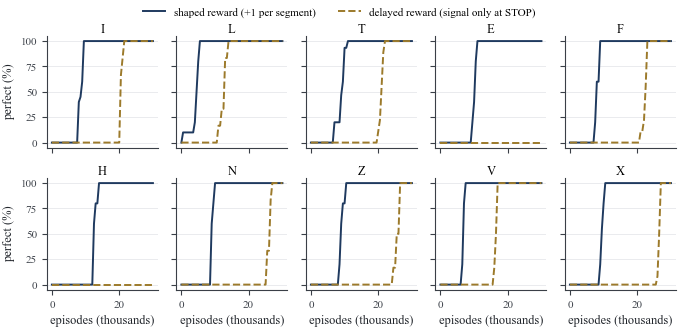

In [9]:
delayed = Rewards(new_segment=0.0)
fig, axes = plt.subplots(2, 5, figsize=(rs.WIDTH, 3.3), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), TRAINING_LETTERS):
    late = [q_learning(LetterWritingEnv(name, rewards=delayed), n_episodes=30_000, alpha=0.5, gamma=GAMMA, seed=s)
            for s in [0, 1, 2]]
    ax.plot(episodes / 1000, 100 * q_curves[f"{name}_perfect"].mean(0), color=rs.NAVY, lw=1.4)
    ax.plot(late[0]["eval_episodes"] / 1000, 100 * np.mean([r["eval_perfect"] for r in late], axis=0),
            color=rs.OCHRE, ls="--", lw=1.4)
    ax.set_ylim(-5, 105)
    ax.set_title(name, pad=2)
    rs.axes_style(ax)
for ax in axes[1]:
    ax.set_xlabel("episodes (thousands)")
for ax in axes[:, 0]:
    ax.set_ylabel("perfect (%)")
fig.legend([plt.Line2D([], [], color=rs.NAVY, lw=1.4), plt.Line2D([], [], color=rs.OCHRE, ls="--", lw=1.4)],
           ["shaped reward (+1 per segment)", "delayed reward (signal only at STOP)"],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save(fig, "fig10_delayed_reward.png")
plt.show()

## Figure 11 — DQN learning curves (3 runs, notebook 07)

saved figures/fig11_dqn_learning.png


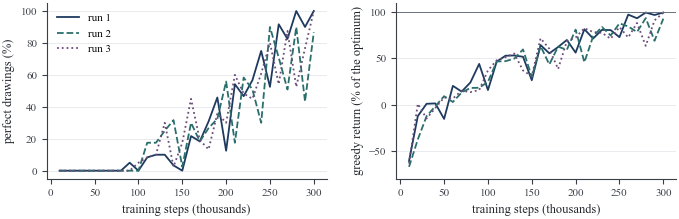

In [10]:
v_vec = np.array([v_star[n] for n in TRAINING_LETTERS])
fig, axes = plt.subplots(1, 2, figsize=(rs.WIDTH, 2.4))
for seed, color, ls in zip([0, 1, 2], rs.SERIES, rs.LINESTYLES):
    d = np.load(f"../results/07_dqn_seed{seed}_curves.npz")
    axes[0].plot(d["eval_steps"] / 1000, 100 * d["perfect"].mean(1), color=color, ls=ls, lw=1.3, label=f"run {seed + 1}")
    axes[1].plot(d["eval_steps"] / 1000, 100 * (d["returns"] / v_vec).mean(1), color=color, ls=ls, lw=1.3)
axes[1].axhline(100, color=rs.SLATE, lw=0.7)
axes[1].set_ylim(-80, 110)
rs.axes_style(axes[0], "training steps (thousands)", "perfect drawings (%)")
rs.axes_style(axes[1], "training steps (thousands)", "greedy return (% of the optimum)")
axes[0].legend(loc="upper left")
fig.tight_layout(w_pad=2)
save(fig, "fig11_dqn_learning.png")
plt.show()

## Figure 12 — The 2 × 2 generalisation design (networks of notebooks 07 and 09)

saved figures/fig12_generalisation.png


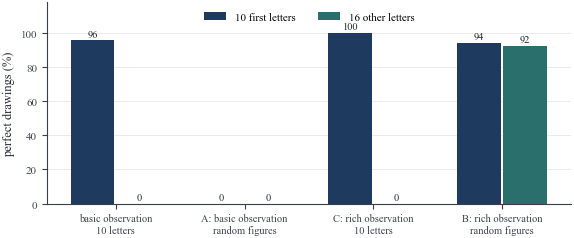

basic observation 10 letters           10 first letters  95.6 %   16 others   0.0 %
A: basic observation random figures    10 first letters   0.0 %   16 others   0.0 %
C: rich observation 10 letters         10 first letters 100.0 %   16 others   0.0 %
B: rich observation random figures     10 first letters  94.2 %   16 others  92.4 %


In [11]:
def load(path, rich):
    net = QNetwork(256, obs_size(rich))
    net.load_state_dict(torch.load(path))
    net.eval()
    return net

def perfect_rate(net, names, rich):
    rates = []
    for name in names:
        env = LetterWritingEnv(name)
        eps = [greedy_episode(net, env, s, GAMMA, rich) for s in env.letter.start_points]
        rates.append(np.mean([e["completed"] and e["off_letter"] == 0 for e in eps]))
    return 100 * np.mean(rates)

net07 = [load(f"../results/07_dqn_seed{s}.pt", False) for s in [0, 1, 2]]
netB = [load("../results/09_dqn_B.pt", True), load("../results/09_dqn_B_seed1.pt", True)]
configs = [("basic observation\n10 letters", net07, False),
           ("A: basic observation\nrandom figures", [load("../results/09_dqn_A.pt", False)], False),
           ("C: rich observation\n10 letters", [load("../results/09_dqn_C.pt", True)], True),
           ("B: rich observation\nrandom figures", netB, True)]
first = [np.mean([perfect_rate(n, TRAINING_LETTERS, rich) for n in nets]) for _, nets, rich in configs]
other = [np.mean([perfect_rate(n, TEST_LETTERS, rich) for n in nets]) for _, nets, rich in configs]

fig, ax = plt.subplots(figsize=(rs.WIDTH * 0.85, 2.6))
x = np.arange(len(configs))
ax.bar(x - 0.18, first, width=0.34, color=rs.NAVY, label="10 first letters")
ax.bar(x + 0.18, other, width=0.34, color=rs.TEAL, label="16 other letters")
for xi, a, b in zip(x, first, other):
    ax.text(xi - 0.18, a + 2, f"{a:.0f}", ha="center", fontsize=7.5, color=rs.TEXT)
    ax.text(xi + 0.18, b + 2, f"{b:.0f}", ha="center", fontsize=7.5, color=rs.TEXT)
ax.set_xticks(x, [c[0] for c in configs], fontsize=7.5)
ax.set_ylim(0, 118)
rs.axes_style(ax, None, "perfect drawings (%)")
ax.legend(loc="upper center", ncol=2)
fig.tight_layout()
save(fig, "fig12_generalisation.png")
plt.show()
for (label, _, _), a, b in zip(configs, first, other):
    print(f"{label.replace(chr(10), ' '):<38} 10 first letters {a:5.1f} %   16 others {b:5.1f} %")

## Figures 13–14 — Unseen letters

saved figures/fig13_unseen_letters.png


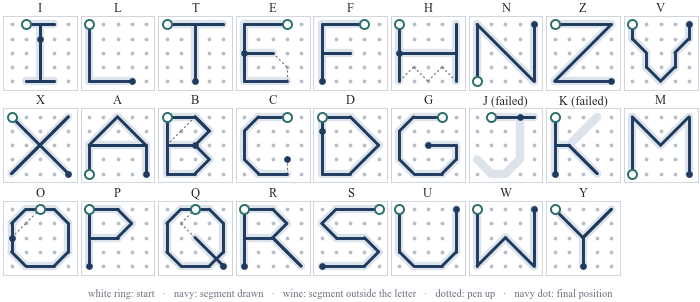

saved figures/fig14_unseen_failures_07.png


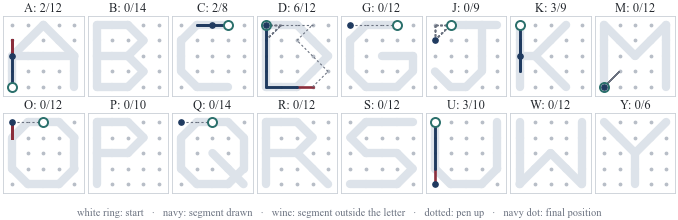


total time: 4.1 min


In [12]:
fig, axes = rs.panel_grid(26, 9, panel=0.78)
for ax, name in zip(axes, TRAINING_LETTERS + TEST_LETTERS):
    env = LetterWritingEnv(name)
    ep = greedy_episode(netB[0], env, env.letter.start_points[0], GAMMA, rich=True)
    ok = ep["completed"] and ep["off_letter"] == 0
    rs.draw_episode(ax, env.letter, ep["history"], name if ok else f"{name} (failed)")
rs.add_caption_line(fig)
fig.tight_layout(pad=0.3)
save(fig, "fig13_unseen_letters.png")
plt.show()

fig, axes = rs.panel_grid(16, 8, panel=0.85)
for ax, name in zip(axes, TEST_LETTERS):
    env = LetterWritingEnv(name)
    ep = greedy_episode(net07[0], env, env.letter.start_points[0], GAMMA)
    rs.draw_episode(ax, env.letter, ep["history"], f"{name}: {ep['drawn']}/{env.k}")
rs.add_caption_line(fig)
fig.tight_layout(pad=0.3)
save(fig, "fig14_unseen_failures_07.png")
plt.show()
print(f"\ntotal time: {(time.perf_counter() - t_start) / 60:.1f} min")